<a href="https://colab.research.google.com/github/dairo123e/Proyecto-Estadisticas-YouTube/blob/main/Proyecto_Estadisticas_YouTube_Avances_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto estadísticas de YouTube: Avances II

**Integrantes:**  
- Dairo Enrique Contreras Quintana  
- Stiven David Álvarez Olmos  

**Docente:** Paul Alexander Díaz Montaña  
**Fecha:** 11 de octubre de 2026

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [3]:
# Cargar los archivos desde la ubicación actual
videos = pd.read_csv("/videos-stats.csv")
comentarios = pd.read_csv("/comments.csv")

print("Dimensiones de videos:", videos.shape)
print("Dimensiones de comentarios:", comentarios.shape)

print("\nPrimeras filas de videos:")
display(videos.head())

print("\nPrimeras filas de comentarios:")
display(comentarios.head())

Dimensiones de videos: (1881, 8)
Dimensiones de comentarios: (18409, 5)

Primeras filas de videos:


,Unnamed: 0,Title,Video ID,Published At,Keyword,Likes,Comments,Views
0,0,Apple Pay Is Killing the Physical Wallet After...,wAZZ-UWGVHI,2022-08-23,tech,3407.0,672.0,135612.0
1,1,The most EXPENSIVE thing I own.,b3x28s61q3c,2022-08-24,tech,76779.0,4306.0,1758063.0
2,2,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,tech,63825.0,3338.0,1564007.0
3,3,Petrol Vs Liquid Nitrogen | Freezing Experimen...,kXiYSI7H2b0,2022-08-23,tech,71566.0,1426.0,922918.0
4,4,Best Back to School Tech 2022!,ErMwWXQxHp0,2022-08-08,tech,96513.0,5155.0,1855644.0



Primeras filas de comentarios:


,Unnamed: 0,Video ID,Comment,Likes,Sentiment
0,0,wAZZ-UWGVHI,Let's not forget that Apple Pay in 2014 requir...,95.0,1.0
1,1,wAZZ-UWGVHI,Here in NZ 50% of retailers don’t even have co...,19.0,0.0
2,2,wAZZ-UWGVHI,I will forever acknowledge this channel with t...,161.0,2.0
3,3,wAZZ-UWGVHI,Whenever I go to a place that doesn’t take App...,8.0,0.0
4,4,wAZZ-UWGVHI,"Apple Pay is so convenient, secure, and easy t...",34.0,2.0


## 1. Revisión y limpieza de los datos

En esta etapa se revisa la estructura, calidad y consistencia de los datos. Se identifican valores faltantes, registros duplicados y valores inválidos antes de realizar los análisis estadísticos y entrenar los modelos.

In [4]:
# Crear copias de trabajo para conservar los archivos originales
videos_limpios = videos.copy()
comentarios_limpios = comentarios.copy()

# Eliminar la columna de índice que no aporta información al análisis
videos_limpios = videos_limpios.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

comentarios_limpios = comentarios_limpios.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

# Convertir la fecha de publicación a formato de fecha
videos_limpios["Published At"] = pd.to_datetime(
    videos_limpios["Published At"],
    errors="coerce"
)

# Convertir valores negativos inválidos en datos faltantes
columnas_numericas_videos = ["Likes", "Comments", "Views"]

for columna in columnas_numericas_videos:
    videos_limpios.loc[
        videos_limpios[columna] < 0,
        columna
    ] = np.nan

# Eliminar registros sin información numérica esencial
videos_limpios = videos_limpios.dropna(
    subset=["Likes", "Comments", "Views"]
)

# Eliminar comentarios sin texto
comentarios_limpios = comentarios_limpios.dropna(
    subset=["Comment"]
)

# Eliminar comentarios vacíos
comentarios_limpios = comentarios_limpios[
    comentarios_limpios["Comment"].astype(str).str.strip() != ""
].copy()

# Eliminar filas completamente duplicadas
videos_limpios = videos_limpios.drop_duplicates()
comentarios_limpios = comentarios_limpios.drop_duplicates()

# Reiniciar los índices
videos_limpios = videos_limpios.reset_index(drop=True)
comentarios_limpios = comentarios_limpios.reset_index(drop=True)

print("LIMPIEZA COMPLETADA")
print("-" * 50)
print("Dimensiones originales de videos:", videos.shape)
print("Dimensiones finales de videos:", videos_limpios.shape)
print()
print("Dimensiones originales de comentarios:", comentarios.shape)
print("Dimensiones finales de comentarios:", comentarios_limpios.shape)
print()
print("Valores faltantes en videos:")
display(videos_limpios.isnull().sum().to_frame("Cantidad"))
print()
print("Valores faltantes en comentarios:")
display(comentarios_limpios.isnull().sum().to_frame("Cantidad"))


LIMPIEZA COMPLETADA
--------------------------------------------------
Dimensiones originales de videos: (1881, 8)
Dimensiones finales de videos: (1870, 7)

Dimensiones originales de comentarios: (18409, 5)
Dimensiones finales de comentarios: (18260, 4)

Valores faltantes en videos:


,Cantidad
Title,0
Video ID,0
Published At,0
Keyword,0
Likes,0
Comments,0
Views,0



Valores faltantes en comentarios:


,Cantidad
Video ID,0
Comment,0
Likes,0
Sentiment,0


## 2. Integración de los videos con la información de los comentarios

Los comentarios se agrupan mediante el identificador de cada video. Para cada video se calculan la cantidad de comentarios analizados, el promedio de likes de los comentarios, el sentimiento promedio y la proporción de comentarios negativos, neutrales y positivos. Estas variables permitirán estudiar la relación entre las reacciones de los usuarios y la popularidad de los videos.
``

In [5]:
# Crear variables indicadoras para cada categoría de sentimiento
comentarios_limpios["Negativo"] = (
    comentarios_limpios["Sentiment"] == 0
).astype(int)

comentarios_limpios["Neutral"] = (
    comentarios_limpios["Sentiment"] == 1
).astype(int)

comentarios_limpios["Positivo"] = (
    comentarios_limpios["Sentiment"] == 2
).astype(int)

# Agrupar los comentarios por video
resumen_comentarios = (
    comentarios_limpios
    .groupby("Video ID")
    .agg(
        comentarios_analizados=("Comment", "count"),
        promedio_likes_comentarios=("Likes", "mean"),
        total_likes_comentarios=("Likes", "sum"),
        sentimiento_promedio=("Sentiment", "mean"),
        comentarios_negativos=("Negativo", "sum"),
        comentarios_neutrales=("Neutral", "sum"),
        comentarios_positivos=("Positivo", "sum")
    )
    .reset_index()
)

# Calcular proporciones de sentimientos
resumen_comentarios["proporcion_negativos"] = (
    resumen_comentarios["comentarios_negativos"]
    / resumen_comentarios["comentarios_analizados"]
)

resumen_comentarios["proporcion_neutrales"] = (
    resumen_comentarios["comentarios_neutrales"]
    / resumen_comentarios["comentarios_analizados"]
)

resumen_comentarios["proporcion_positivos"] = (
    resumen_comentarios["comentarios_positivos"]
    / resumen_comentarios["comentarios_analizados"]
)

print("Resumen de comentarios creado correctamente")
print("Dimensiones:", resumen_comentarios.shape)

display(resumen_comentarios.head())

Resumen de comentarios creado correctamente
Dimensiones: (1869, 11)


,Video ID,comentarios_analizados,promedio_likes_comentarios,total_likes_comentarios,sentimiento_promedio,comentarios_negativos,comentarios_neutrales,comentarios_positivos,proporcion_negativos,proporcion_neutrales,proporcion_positivos
0,--ZI0dSbbNU,10,2553.9,25539.0,1.9,0,1,9,0.0,0.1,0.9
1,--hxd1CrOqg,10,44.6,446.0,0.2,8,2,0,0.8,0.2,0.0
2,--ixiTypG8g,10,83.6,836.0,0.2,8,2,0,0.8,0.2,0.0
3,-64r1hcxtV4,10,5550.0,55500.0,1.5,2,1,7,0.2,0.1,0.7
4,-6IgkG5yZfo,10,445.2,4452.0,2.0,0,0,10,0.0,0.0,1.0


In [6]:
# Conservar un único registro por Video ID
# Algunos videos aparecen relacionados con más de una palabra clave
videos_unicos = (
    videos_limpios
    .sort_values("Video ID")
    .drop_duplicates(subset=["Video ID"], keep="first")
    .reset_index(drop=True)
)

# Unir la información de los videos con el resumen de comentarios
datos = videos_unicos.merge(
    resumen_comentarios,
    on="Video ID",
    how="inner"
)

print("INTEGRACIÓN COMPLETADA")
print("-" * 50)
print("Videos antes de controlar identificadores repetidos:", len(videos_limpios))
print("Videos únicos:", len(videos_unicos))
print("Registros finales integrados:", len(datos))
print("Número de columnas finales:", datos.shape[1])
print("Valores faltantes totales:", datos.isnull().sum().sum())

display(datos.head())


INTEGRACIÓN COMPLETADA
--------------------------------------------------
Videos antes de controlar identificadores repetidos: 1870
Videos únicos: 1859
Registros finales integrados: 1859
Número de columnas finales: 17
Valores faltantes totales: 0


,Title,Video ID,Published At,Keyword,Likes,Comments,Views,comentarios_analizados,promedio_likes_comentarios,total_likes_comentarios,sentimiento_promedio,comentarios_negativos,comentarios_neutrales,comentarios_positivos,proporcion_negativos,proporcion_neutrales,proporcion_positivos
0,ASMR MUKBANG DOUBLE BIG MAC &amp; CHEESY HASH ...,--ZI0dSbbNU,2020-04-18,mukbang,378858.0,18860.0,17975269.0,10,2553.9,25539.0,1.9,0,1,9,0.0,0.1,0.9
1,Deadly car bomb detonates outside Moscow,--hxd1CrOqg,2022-08-22,news,6379.0,4853.0,808787.0,10,44.6,446.0,0.2,8,2,0,0.8,0.2,0.0
2,How Biden&#39;s student loan forgiveness progr...,--ixiTypG8g,2022-08-24,news,1029.0,2347.0,97434.0,10,83.6,836.0,0.2,8,2,0,0.8,0.2,0.0
3,Celebrating My 400 Pound Milestone.... McDonal...,-64r1hcxtV4,2022-05-30,mukbang,45628.0,17264.0,5283664.0,10,5550.0,55500.0,1.5,2,1,7,0.2,0.1,0.7
4,Physics Review - Basic Introduction,-6IgkG5yZfo,2017-01-02,physics,10959.0,525.0,844015.0,10,445.2,4452.0,2.0,0,0,10,0.0,0.0,1.0


## 3. Definición de la variable objetivo

El objetivo del proyecto es predecir el nivel de popularidad de un video de YouTube. Para ello, se utiliza la mediana de visualizaciones como punto de corte. Los videos con una cantidad de visualizaciones superior a la mediana se clasifican con popularidad alta, mientras que los demás se clasifican con popularidad baja. Este criterio permite construir una variable objetivo equilibrada y abordar el problema mediante modelos de clasificación.

In [7]:
# Calcular la mediana de visualizaciones
mediana_visualizaciones = datos["Views"].median()

# Crear la variable objetivo
# 0 = popularidad baja
# 1 = popularidad alta
datos["popularidad_alta"] = (
    datos["Views"] > mediana_visualizaciones
).astype(int)

# Crear etiquetas para las gráficas
datos["nivel_popularidad"] = datos["popularidad_alta"].map({
    0: "Baja",
    1: "Alta"
})

print("Mediana de visualizaciones:", round(mediana_visualizaciones, 2))
print("\nDistribución de la variable objetivo:")
display(datos["nivel_popularidad"].value_counts().to_frame("Cantidad"))

print("\nDistribución porcentual:")
display(
    datos["nivel_popularidad"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Porcentaje")
)

Mediana de visualizaciones: 589907.0

Distribución de la variable objetivo:


,Cantidad
nivel_popularidad,
Baja,930
Alta,929



Distribución porcentual:


,Porcentaje
nivel_popularidad,
Baja,50.03
Alta,49.97


In [8]:
# Crear variables derivadas para los análisis y modelos

# Longitud del título
datos["longitud_titulo"] = (
    datos["Title"]
    .astype(str)
    .str.len()
)

# Antigüedad del video en días respecto a la fecha más reciente del dataset
fecha_referencia = datos["Published At"].max()

datos["antiguedad_dias"] = (
    fecha_referencia - datos["Published At"]
).dt.days

# Transformaciones logarítmicas para reducir el efecto de valores extremos
datos["log_likes_video"] = np.log1p(datos["Likes"])
datos["log_comentarios_video"] = np.log1p(datos["Comments"])
datos["log_promedio_likes_comentarios"] = np.log1p(
    datos["promedio_likes_comentarios"]
)

print("Variables adicionales creadas correctamente")

display(
    datos[
        [
            "Title",
            "longitud_titulo",
            "antiguedad_dias",
            "log_likes_video",
            "log_comentarios_video",
            "nivel_popularidad"
        ]
    ].head()
)

Variables adicionales creadas correctamente


,Title,longitud_titulo,antiguedad_dias,log_likes_video,log_comentarios_video,nivel_popularidad
0,ASMR MUKBANG DOUBLE BIG MAC &amp; CHEESY HASH ...,101,858,12.844919,9.844852,Alta
1,Deadly car bomb detonates outside Moscow,40,2,8.760923,8.487558,Alta
2,How Biden&#39;s student loan forgiveness progr...,58,0,6.937314,7.761319,Baja
3,Celebrating My 400 Pound Milestone.... McDonal...,61,86,10.728299,9.756437,Alta
4,Physics Review - Basic Introduction,35,2060,9.302008,6.265301,Alta


In [9]:
print("Dimensiones finales:", datos.shape)
print("Valores faltantes:", datos.isnull().sum().sum())

print("\nTipos de variables:")
display(datos.dtypes.to_frame("Tipo de dato"))

Dimensiones finales: (1859, 24)
Valores faltantes: 0

Tipos de variables:


,Tipo de dato
Title,object
Video ID,object
Published At,datetime64[ns]
Keyword,object
Likes,float64
Comments,float64
Views,float64
comentarios_analizados,int64
promedio_likes_comentarios,float64
total_likes_comentarios,float64


## 4. Análisis estadístico exploratorio

Se realizó un análisis estadístico para estudiar la distribución de las visualizaciones, los “likes”, la cantidad de comentarios y el sentimiento de los usuarios. También se analizaron las relaciones entre estas variables y el nivel de popularidad del video. Debido a la presencia de valores extremos, se emplearon transformaciones logarítmicas para facilitar la interpretación de las distribuciones y correlaciones.

In [10]:
# Seleccionar las variables principales para el análisis descriptivo
variables_descriptivas = [
    "Views",
    "Likes",
    "Comments",
    "comentarios_analizados",
    "promedio_likes_comentarios",
    "sentimiento_promedio",
    "proporcion_negativos",
    "proporcion_neutrales",
    "proporcion_positivos",
    "longitud_titulo",
    "antiguedad_dias"
]

estadisticas = (
    datos[variables_descriptivas]
    .describe()
    .T
    .round(2)
)

# Agregar la mediana para fortalecer el análisis
estadisticas["mediana"] = (
    datos[variables_descriptivas]
    .median()
    .round(2)
)

# Ordenar las columnas
estadisticas = estadisticas[
    ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
]

display(estadisticas)

,count,mean,mediana,std,min,25%,50%,75%,max
Views,1859.0,11695263.09,589907.0,1.090211e+08,25.0,85121.50,589907.0,2804977.50,4.034122e+09
Likes,1859.0,169827.49,14899.0,7.976421e+05,0.0,2703.50,14899.0,61011.00,1.644556e+07
Comments,1859.0,7847.48,818.0,3.799758e+04,0.0,201.00,818.0,3395.00,7.328180e+05
comentarios_analizados,1859.0,9.77,10.0,1.170000e+00,1.0,10.00,10.0,10.00,1.800000e+01
promedio_likes_comentarios,1859.0,1021.13,107.1,5.058340e+03,0.0,16.35,107.1,665.45,1.739622e+05
sentimiento_promedio,1859.0,1.49,1.6,4.200000e-01,0.0,1.24,1.6,1.80,2.000000e+00
proporcion_negativos,1859.0,0.13,0.1,1.800000e-01,0.0,0.00,0.1,0.20,1.000000e+00
proporcion_neutrales,1859.0,0.26,0.2,2.200000e-01,0.0,0.10,0.2,0.40,1.000000e+00
proporcion_positivos,1859.0,0.62,0.7,2.800000e-01,0.0,0.40,0.7,0.80,1.000000e+00
longitud_titulo,1859.0,57.89,56.0,2.197000e+01,3.0,40.50,56.0,73.00,1.140000e+02


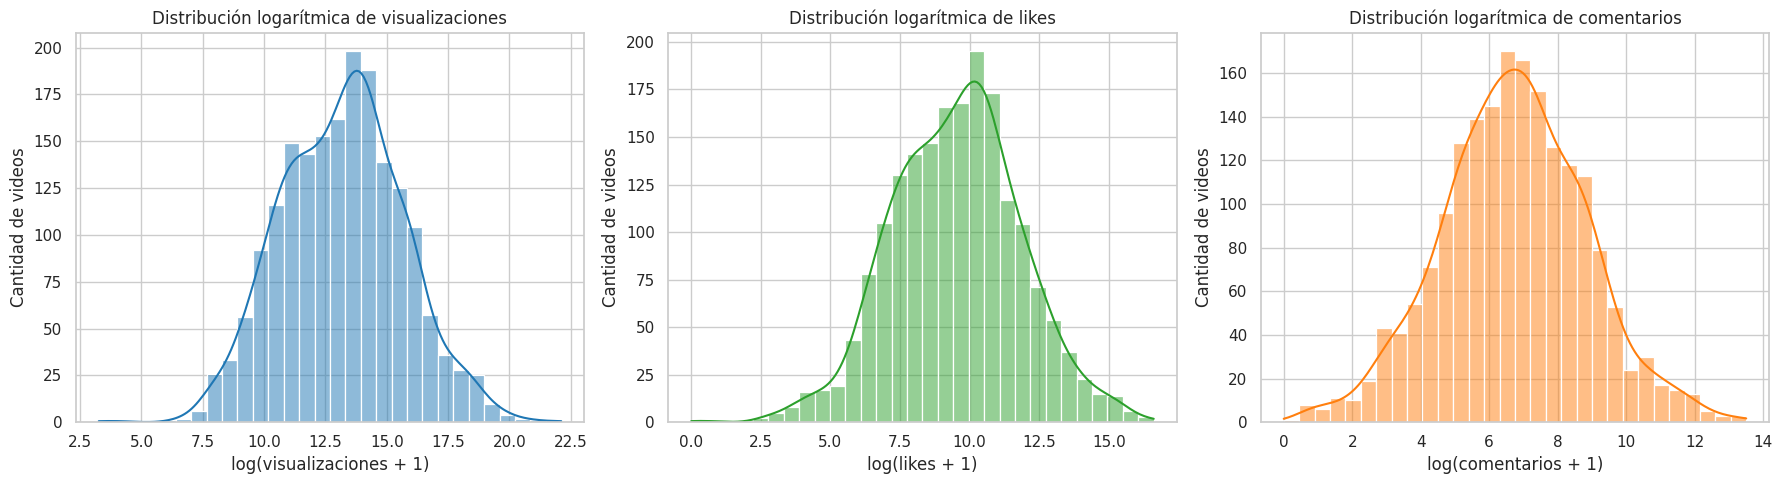

In [11]:
# Crear transformaciones logarítmicas adicionales para las gráficas
datos["log_visualizaciones"] = np.log1p(datos["Views"])

# Graficar distribuciones transformadas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    data=datos,
    x="log_visualizaciones",
    bins=30,
    kde=True,
    ax=axes[0],
    color="#1f77b4"
)
axes[0].set_title("Distribución logarítmica de visualizaciones")
axes[0].set_xlabel("log(visualizaciones + 1)")
axes[0].set_ylabel("Cantidad de videos")

sns.histplot(
    data=datos,
    x="log_likes_video",
    bins=30,
    kde=True,
    ax=axes[1],
    color="#2ca02c"
)
axes[1].set_title("Distribución logarítmica de likes")
axes[1].set_xlabel("log(likes + 1)")
axes[1].set_ylabel("Cantidad de videos")

sns.histplot(
    data=datos,
    x="log_comentarios_video",
    bins=30,
    kde=True,
    ax=axes[2],
    color="#ff7f0e"
)
axes[2].set_title("Distribución logarítmica de comentarios")
axes[2].set_xlabel("log(comentarios + 1)")
axes[2].set_ylabel("Cantidad de videos")

plt.tight_layout()
plt.show()

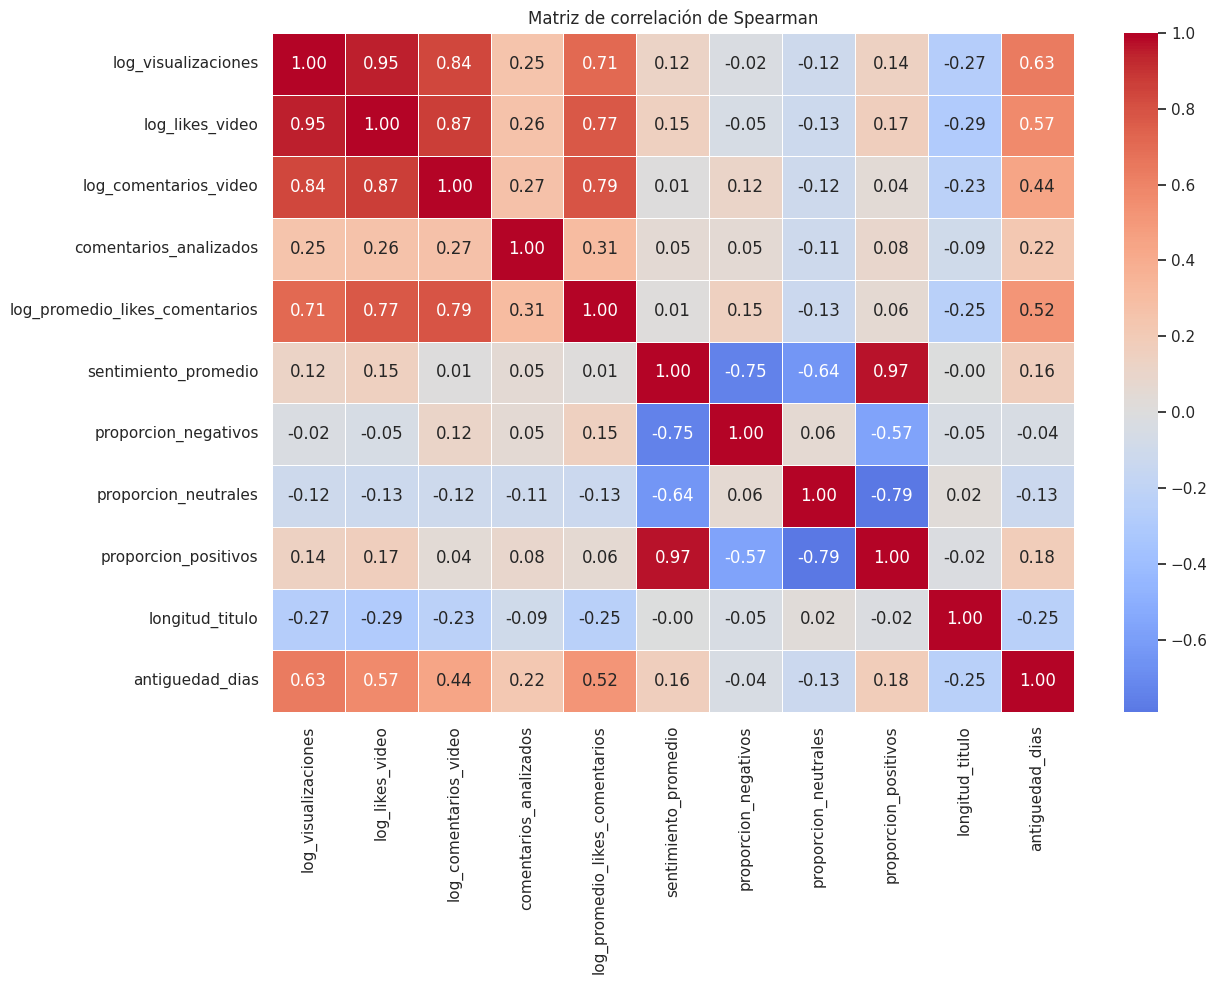

In [12]:
# Variables seleccionadas para estudiar sus correlaciones
variables_correlacion = [
    "log_visualizaciones",
    "log_likes_video",
    "log_comentarios_video",
    "comentarios_analizados",
    "log_promedio_likes_comentarios",
    "sentimiento_promedio",
    "proporcion_negativos",
    "proporcion_neutrales",
    "proporcion_positivos",
    "longitud_titulo",
    "antiguedad_dias"
]

matriz_correlacion = (
    datos[variables_correlacion]
    .corr(method="spearman")
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlación de Spearman")
plt.tight_layout()
plt.show()


In [13]:
# Ordenar las correlaciones respecto a las visualizaciones
correlaciones_visualizaciones = (
    matriz_correlacion["log_visualizaciones"]
    .drop("log_visualizaciones")
    .sort_values(ascending=False)
    .to_frame("Correlación con visualizaciones")
)

display(correlaciones_visualizaciones.round(3))

,Correlación con visualizaciones
log_likes_video,0.949
log_comentarios_video,0.839
log_promedio_likes_comentarios,0.713
antiguedad_dias,0.632
comentarios_analizados,0.252
proporcion_positivos,0.142
sentimiento_promedio,0.122
proporcion_negativos,-0.023
proporcion_neutrales,-0.118
longitud_titulo,-0.267


### Interpretación del análisis de correlación

El análisis de correlación de Spearman muestra que la cantidad de likes del video presenta la relación positiva más fuerte con las visualizaciones (ρ = 0,949). También se observa una correlación alta entre el número de comentarios del video y las visualizaciones (ρ = 0,839), así como entre el promedio de likes de los comentarios y las visualizaciones (ρ = 0,713). Estos resultados indican que los videos con mayor interacción tienden a alcanzar una mayor cantidad de visualizaciones.

La antigüedad del video presenta una correlación positiva moderada-alta con las visualizaciones (ρ = 0,632), lo que sugiere que los videos publicados desde hace más tiempo han tenido mayores oportunidades de acumular visitas. Por otra parte, la proporción de comentarios positivos tiene una relación positiva débil con las visualizaciones (ρ = 0,142), mientras que el sentimiento promedio también presenta una relación débil (ρ = 0,122). Por tanto, el sentimiento de los comentarios podría aportar información complementaria, pero no parece explicar por sí solo la popularidad.

La longitud del título presenta una correlación negativa débil con las visualizaciones (ρ = -0,267). Esto indica que, dentro del dataset analizado, los títulos más largos tienden a relacionarse con una menor cantidad de visualizaciones, aunque este resultado no implica causalidad.

También se identificaron correlaciones altas entre algunas variables predictoras. Por ejemplo, los likes y los comentarios del video presentan una correlación de 0,87, mientras que el sentimiento promedio y la proporción de comentarios positivos presentan una correlación de 0,97. Esta multicolinealidad debe considerarse durante la selección de variables, especialmente en modelos lineales. Por esta razón, se compararán modelos lineales y modelos basados en árboles.

### Comparación entre videos de popularidad alta y baja

Se comparan las principales características de los videos clasificados con popularidad alta y baja. Este análisis permite determinar cuáles variables presentan diferencias relevantes entre ambos grupos y cuáles podrían resultar útiles para los modelos predictivos.

In [15]:
# Variables seleccionadas para comparar los niveles de popularidad
variables_comparacion = [
    "log_likes_video",
    "log_comentarios_video",
    "log_promedio_likes_comentarios",
    "comentarios_analizados",
    "sentimiento_promedio",
    "proporcion_negativos",
    "proporcion_neutrales",
    "proporcion_positivos",
    "longitud_titulo",
    "antiguedad_dias"
]

# Calcular medianas por nivel de popularidad
comparacion_popularidad = (
    datos.groupby("nivel_popularidad")[variables_comparacion]
    .median()
    .T
    .round(3)
)

comparacion_popularidad["Diferencia_Alta_menos_Baja"] = (
    comparacion_popularidad["Alta"]
    - comparacion_popularidad["Baja"]
).round(3)

display(comparacion_popularidad)

nivel_popularidad,Alta,Baja,Diferencia_Alta_menos_Baja
log_likes_video,11.019,7.905,3.114
log_comentarios_video,8.019,5.421,2.598
log_promedio_likes_comentarios,6.357,3.200,3.157
comentarios_analizados,10.000,10.000,0.000
sentimiento_promedio,1.600,1.500,0.100
proporcion_negativos,0.100,0.100,0.000
proporcion_neutrales,0.200,0.200,0.000
proporcion_positivos,0.700,0.600,0.100
longitud_titulo,50.000,61.000,-11.000
antiguedad_dias,304.000,2.000,302.000


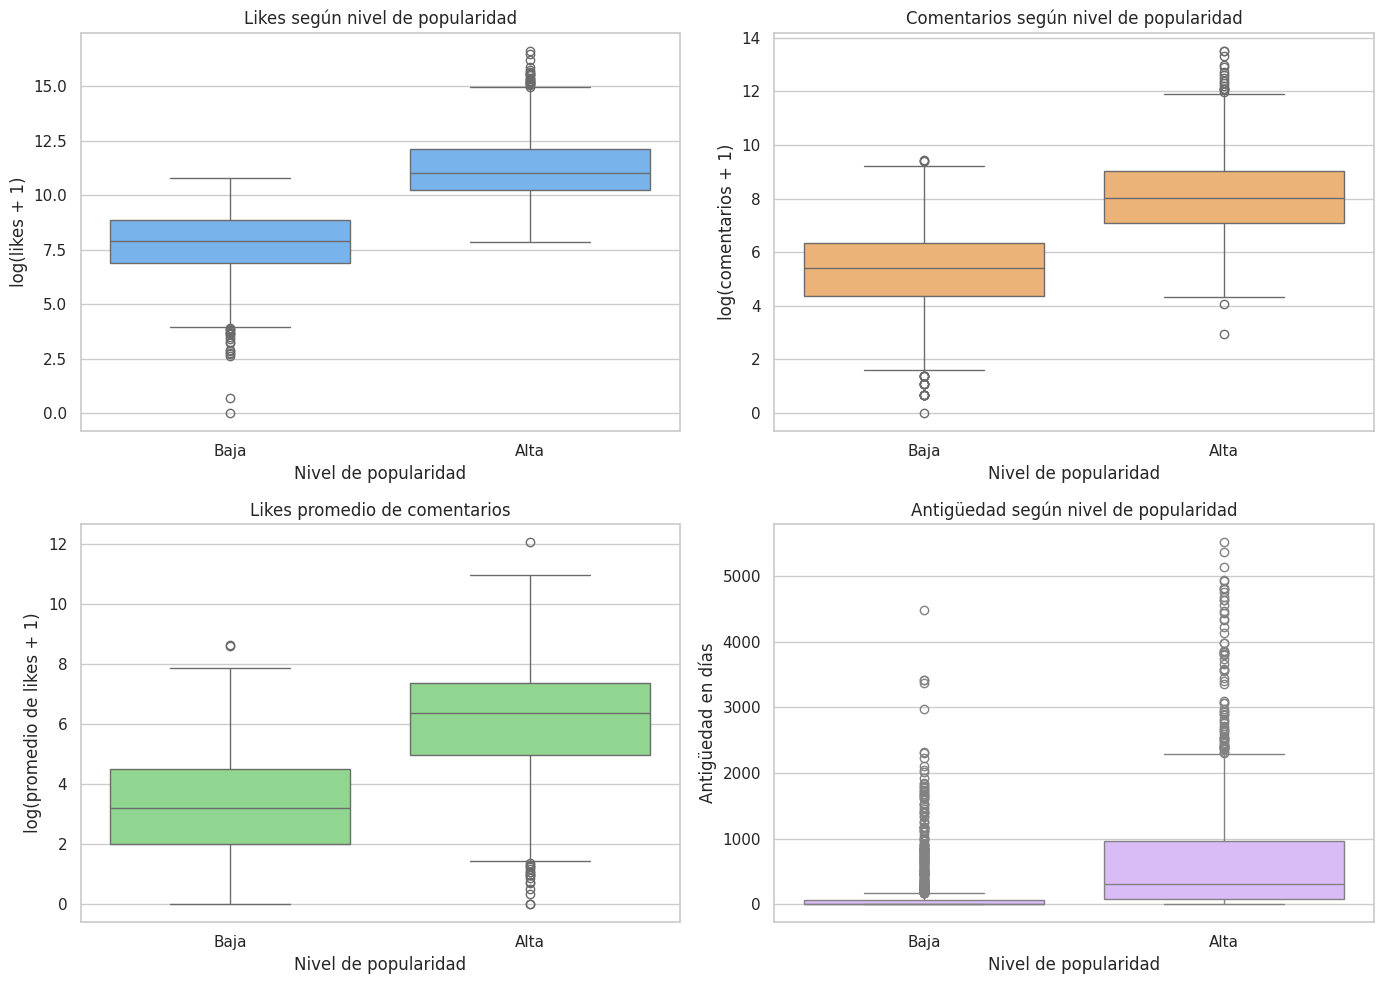

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(
    data=datos,
    x="nivel_popularidad",
    y="log_likes_video",
    order=["Baja", "Alta"],
    ax=axes[0, 0],
    color="#66b3ff"
)
axes[0, 0].set_title("Likes según nivel de popularidad")
axes[0, 0].set_xlabel("Nivel de popularidad")
axes[0, 0].set_ylabel("log(likes + 1)")

sns.boxplot(
    data=datos,
    x="nivel_popularidad",
    y="log_comentarios_video",
    order=["Baja", "Alta"],
    ax=axes[0, 1],
    color="#ffb366"
)
axes[0, 1].set_title("Comentarios según nivel de popularidad")
axes[0, 1].set_xlabel("Nivel de popularidad")
axes[0, 1].set_ylabel("log(comentarios + 1)")

sns.boxplot(
    data=datos,
    x="nivel_popularidad",
    y="log_promedio_likes_comentarios",
    order=["Baja", "Alta"],
    ax=axes[1, 0],
    color="#85e085"
)
axes[1, 0].set_title("Likes promedio de comentarios")
axes[1, 0].set_xlabel("Nivel de popularidad")
axes[1, 0].set_ylabel("log(promedio de likes + 1)")

sns.boxplot(
    data=datos,
    x="nivel_popularidad",
    y="antiguedad_dias",
    order=["Baja", "Alta"],
    ax=axes[1, 1],
    color="#d9b3ff"
)
axes[1, 1].set_title("Antigüedad según nivel de popularidad")
axes[1, 1].set_xlabel("Nivel de popularidad")
axes[1, 1].set_ylabel("Antigüedad en días")

plt.tight_layout()
plt.show()


In [17]:
from scipy.stats import mannwhitneyu

resultados_pruebas = []

for variable in variables_comparacion:
    grupo_baja = datos.loc[
        datos["popularidad_alta"] == 0,
        variable
    ]

    grupo_alta = datos.loc[
        datos["popularidad_alta"] == 1,
        variable
    ]

    estadistico, valor_p = mannwhitneyu(
        grupo_baja,
        grupo_alta,
        alternative="two-sided"
    )

    resultados_pruebas.append({
        "Variable": variable,
        "Mediana popularidad baja": grupo_baja.median(),
        "Mediana popularidad alta": grupo_alta.median(),
        "Estadístico U": estadistico,
        "Valor p": valor_p,
        "Diferencia significativa": "Sí" if valor_p < 0.05 else "No"
    })

resultados_pruebas = pd.DataFrame(resultados_pruebas)

resultados_pruebas = resultados_pruebas.sort_values(
    by="Valor p"
).reset_index(drop=True)

display(
    resultados_pruebas.style.format({
        "Mediana popularidad baja": "{:.3f}",
        "Mediana popularidad alta": "{:.3f}",
        "Estadístico U": "{:.1f}",
        "Valor p": "{:.6f}"
    })
)

,Variable,Mediana popularidad baja,Mediana popularidad alta,Estadístico U,Valor p,Diferencia significativa
0,log_likes_video,7.905,11.019,23745.0,0.000000,Sí
1,log_comentarios_video,5.421,8.019,77104.0,0.000000,Sí
2,log_promedio_likes_comentarios,3.200,6.357,124113.0,0.000000,Sí
3,antiguedad_dias,2.000,304.000,155255.0,0.000000,Sí
4,longitud_titulo,61.000,50.000,534690.0,0.000000,Sí
5,comentarios_analizados,10.000,10.000,391995.0,0.000000,Sí
6,proporcion_positivos,0.600,0.700,366292.5,0.000000,Sí
7,sentimiento_promedio,1.500,1.600,374096.5,0.000001,Sí
8,proporcion_neutrales,0.200,0.200,483697.0,0.000006,Sí
9,proporcion_negativos,0.100,0.100,445868.0,0.198432,No


### Interpretación de las pruebas estadísticas

La prueba U de Mann-Whitney permitió comparar las características de los videos con popularidad alta y baja. Los resultados muestran diferencias estadísticamente significativas en nueve de las diez variables analizadas, con valores p inferiores a 0,05.

Las diferencias más importantes se observaron en las variables de interacción. Los videos de popularidad alta presentaron una mediana de log-likes de 11,019, frente a 7,905 en los videos de popularidad baja. También mostraron una mediana superior de log-comentarios, con 8,019 frente a 5,421, y un promedio mayor de likes en los comentarios, con 6,357 frente a 3,200 en escala logarítmica.

La antigüedad también presentó una diferencia significativa. Los videos de popularidad alta tuvieron una mediana de 304 días, mientras que los videos de popularidad baja presentaron una mediana de 2 días. Esto sugiere que el tiempo disponible para acumular visualizaciones influye en la clasificación de popularidad.

Los videos de popularidad alta presentaron una proporción mediana de comentarios positivos de 0,70, frente a 0,60 en los videos de popularidad baja. Asimismo, el sentimiento promedio fue ligeramente superior en los videos populares. Sin embargo, estas diferencias fueron menores que las observadas en las métricas de interacción.

La longitud del título también mostró una diferencia significativa: los videos de popularidad alta presentaron una mediana de 50 caracteres, mientras que los de popularidad baja alcanzaron 61 caracteres. En este conjunto de datos, los videos populares tienden a utilizar títulos más cortos.

La proporción de comentarios negativos fue la única variable sin una diferencia estadísticamente significativa, debido a que obtuvo un valor p de 0,198432. Además, ambos grupos presentaron una mediana de 0,10. Por esta razón, esta variable tendrá menor prioridad en la construcción de los modelos.

Aunque la cantidad de comentarios analizados presentó una diferencia estadísticamente significativa, ambos grupos tuvieron una mediana de 10 comentarios. Esto indica que la diferencia puede encontrarse en la distribución completa y no necesariamente en la tendencia central. En general, los resultados respaldan la utilización de las métricas de interacción, antigüedad, categoría, longitud del título y composición de sentimientos como variables predictoras.


## 5. Selección de variables y construcción de modelos

La variable objetivo corresponde al nivel de popularidad del video, donde 0 representa popularidad baja y 1 representa popularidad alta. Para la predicción se seleccionaron variables relacionadas con la interacción, la antigüedad, la categoría, las características del título y el sentimiento de los comentarios.

Se excluyeron la cantidad de visualizaciones y las variables derivadas directamente de las visualizaciones, debido a que fueron utilizadas para crear la variable objetivo. También se evitaron variables redundantes con correlaciones excesivamente altas. Los datos se dividieron en conjuntos de entrenamiento y prueba, conservando la proporción de ambas clases.

Se compararon un modelo base, regresión logística, árbol de decisión, Random Forest y Gradient Boosting. Todos los modelos fueron evaluados sobre la misma división de datos y mediante accuracy, precision, recall, F1-score y ROC-AUC.
``

In [22]:
# Variables numéricas seleccionadas
variables_numericas_modelo = [
    "log_likes_video",
    "log_comentarios_video",
    "log_promedio_likes_comentarios",
    "comentarios_analizados",
    "proporcion_negativos",
    "proporcion_neutrales",
    "proporcion_positivos",
    "longitud_titulo",
    "antiguedad_dias"
]

# Variable categórica
variables_categoricas_modelo = [
    "Keyword"
]

# Construir matriz de predictores
X = datos[
    variables_numericas_modelo
    + variables_categoricas_modelo
].copy()

# Variable que se desea predecir
y = datos["popularidad_alta"].copy()

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATOS PREPARADOS")
print("-" * 45)
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Cantidad de variables iniciales:", X.shape[1])

print("\nDistribución en entrenamiento:")
display(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Porcentaje")
)

print("\nDistribución en prueba:")
display(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Porcentaje")
)

DATOS PREPARADOS
---------------------------------------------
Registros de entrenamiento: 1487
Registros de prueba: 372
Cantidad de variables iniciales: 10

Distribución en entrenamiento:


,Porcentaje
popularidad_alta,
0,50.03
1,49.97



Distribución en prueba:


,Porcentaje
popularidad_alta,
1,50.0
0,50.0


In [23]:
# Preprocesamiento de variables numéricas
transformador_numerico = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalamiento", StandardScaler())
    ]
)

# Preprocesamiento de la variable categórica
transformador_categorico = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# Combinar ambos tipos de preprocesamiento
preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            transformador_numerico,
            variables_numericas_modelo
        ),
        (
            "categoricas",
            transformador_categorico,
            variables_categoricas_modelo
        )
    ]
)

print("Preprocesamiento configurado correctamente")

Preprocesamiento configurado correctamente


In [24]:
# Modelos seleccionados para la comparación
modelos = {
    "Modelo base": DummyClassifier(
        strategy="most_frequent"
    ),

    "Regresión logística": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=6,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Cantidad de modelos:", len(modelos))

for nombre in modelos:
    print("-", nombre)


Cantidad de modelos: 5
- Modelo base
- Regresión logística
- Árbol de decisión
- Random Forest
- Gradient Boosting


In [25]:
# Lista para almacenar los resultados
resultados_modelos = []

# Diccionario para guardar los modelos ya entrenados
modelos_entrenados = {}

for nombre, modelo in modelos.items():

    # Crear el pipeline completo
    pipeline_modelo = Pipeline(
        steps=[
            ("preprocesamiento", preprocesador),
            ("modelo", modelo)
        ]
    )

    # Entrenar el modelo
    pipeline_modelo.fit(X_train, y_train)

    # Realizar predicciones
    predicciones = pipeline_modelo.predict(X_test)

    # Calcular probabilidades para ROC-AUC
    probabilidades = pipeline_modelo.predict_proba(X_test)[:, 1]

    # Calcular métricas
    resultados_modelos.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision": precision_score(
            y_test,
            predicciones,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predicciones,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test,
            predicciones,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probabilidades
        )
    })

    # Guardar el pipeline entrenado
    modelos_entrenados[nombre] = pipeline_modelo

    print(nombre, "entrenado correctamente")

# Convertir los resultados en una tabla
tabla_resultados = pd.DataFrame(resultados_modelos)

# Ordenar por F1-score y ROC-AUC
tabla_resultados = tabla_resultados.sort_values(
    by=["F1-score", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

print("\nCOMPARACIÓN DE MODELOS")

display(
    tabla_resultados.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

Modelo base entrenado correctamente
Regresión logística entrenado correctamente
Árbol de decisión entrenado correctamente
Random Forest entrenado correctamente
Gradient Boosting entrenado correctamente

COMPARACIÓN DE MODELOS


,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,0.9409,0.9505,0.9301,0.9402,0.9880
1,Regresión logística,0.9328,0.9305,0.9355,0.9330,0.9851
2,Random Forest,0.9274,0.9441,0.9086,0.9260,0.9860
3,Árbol de decisión,0.9167,0.9282,0.9032,0.9155,0.9794
4,Modelo base,0.5000,0.0000,0.0000,0.0000,0.5000


### Comparación inicial de los modelos

Se probaron cinco modelos: un modelo base, regresión logística, árbol de decisión, Random Forest y Gradient Boosting. Todos los modelos predictivos superaron ampliamente al modelo base, que obtuvo una exactitud de 0,5000 y un ROC-AUC de 0,5000.

Gradient Boosting presentó el mejor desempeño general, con una exactitud de 0,9409, precisión de 0,9505, recall de 0,9301, F1-score de 0,9402 y ROC-AUC de 0,9880. Esto significa que el modelo clasificó correctamente aproximadamente el 94,09 % de los videos y mostró una excelente capacidad para distinguir entre popularidad alta y baja.

La regresión logística obtuvo el segundo mejor F1-score, con 0,9330, mientras que Random Forest alcanzó un F1-score de 0,9260. Aunque Random Forest presentó una precisión elevada de 0,9441, su recall fue inferior al de Gradient Boosting y la regresión logística.

El árbol de decisión produjo resultados adecuados, pero inferiores a los modelos restantes, con un F1-score de 0,9155. En consecuencia, Gradient Boosting se selecciona inicialmente como el mejor modelo por presentar el mayor equilibrio entre precisión, recall y F1-score, además del ROC-AUC más alto.

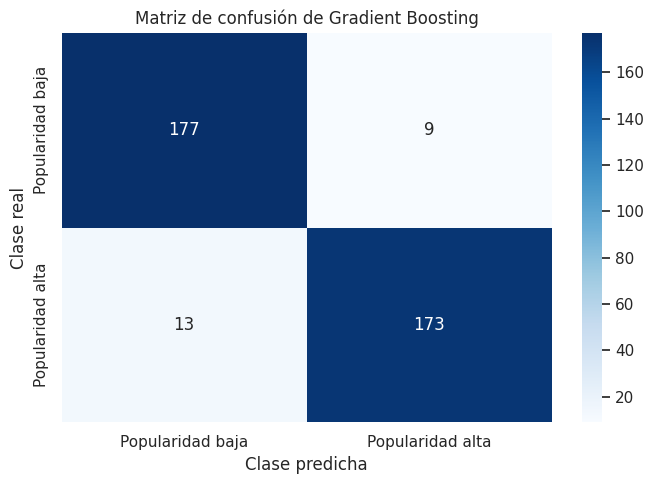

REPORTE DE CLASIFICACIÓN
                  precision    recall  f1-score   support

Popularidad baja     0.9316    0.9516    0.9415       186
Popularidad alta     0.9505    0.9301    0.9402       186

        accuracy                         0.9409       372
       macro avg     0.9411    0.9409    0.9409       372
    weighted avg     0.9411    0.9409    0.9409       372



In [27]:
# Seleccionar el mejor modelo
nombre_mejor_modelo = "Gradient Boosting"
mejor_modelo = modelos_entrenados[nombre_mejor_modelo]

# Predicciones del mejor modelo
predicciones_mejor_modelo = mejor_modelo.predict(X_test)

# Matriz de confusión
matriz = confusion_matrix(
    y_test,
    predicciones_mejor_modelo
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Popularidad baja", "Popularidad alta"],
    yticklabels=["Popularidad baja", "Popularidad alta"]
)

plt.title("Matriz de confusión de Gradient Boosting")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

print("REPORTE DE CLASIFICACIÓN")
print(
    classification_report(
        y_test,
        predicciones_mejor_modelo,
        target_names=[
            "Popularidad baja",
            "Popularidad alta"
        ],
        digits=4
    )
)

### Interpretación de la matriz de confusión

La matriz de confusión muestra que Gradient Boosting clasificó correctamente 350 de los 372 videos incluidos en el conjunto de prueba. El modelo identificó correctamente 177 videos de popularidad baja y 173 videos de popularidad alta.

Respecto a los errores, 9 videos de popularidad baja fueron clasificados incorrectamente como videos de popularidad alta, mientras que 13 videos de popularidad alta fueron clasificados como videos de popularidad baja. En total, el modelo cometió 22 errores de clasificación.

Para la clase de popularidad baja, el modelo obtuvo una precisión de 0,9316, un recall de 0,9516 y un F1-score de 0,9415. Para la clase de popularidad alta, alcanzó una precisión de 0,9505, un recall de 0,9301 y un F1-score de 0,9402.

Los resultados son equilibrados entre ambas clases, debido a que los valores de precisión, recall y F1-score son similares. La exactitud general fue de 0,9409, lo que significa que el modelo clasificó correctamente aproximadamente el 94,09 % de los videos de prueba.

Aunque el modelo presentó un desempeño elevado, se observa una cantidad ligeramente mayor de falsos negativos que de falsos positivos. Es decir, tuvo mayor dificultad para identificar algunos videos realmente populares que para descartar videos de popularidad baja.


In [28]:
resultados_validacion = []

for nombre, pipeline_modelo in modelos_entrenados.items():

    if nombre == "Modelo base":
        continue

    puntajes_f1 = cross_val_score(
        pipeline_modelo,
        X,
        y,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    resultados_validacion.append({
        "Modelo": nombre,
        "F1 promedio": puntajes_f1.mean(),
        "Desviación estándar": puntajes_f1.std(),
        "F1 mínimo": puntajes_f1.min(),
        "F1 máximo": puntajes_f1.max()
    })

tabla_validacion = pd.DataFrame(resultados_validacion)

tabla_validacion = tabla_validacion.sort_values(
    by="F1 promedio",
    ascending=False
).reset_index(drop=True)

print("VALIDACIÓN CRUZADA DE CINCO PARTICIONES")

display(
    tabla_validacion.style.format({
        "F1 promedio": "{:.4f}",
        "Desviación estándar": "{:.4f}",
        "F1 mínimo": "{:.4f}",
        "F1 máximo": "{:.4f}"
    })
)


VALIDACIÓN CRUZADA DE CINCO PARTICIONES


,Modelo,F1 promedio,Desviación estándar,F1 mínimo,F1 máximo
0,Gradient Boosting,0.9386,0.0053,0.9305,0.9468
1,Regresión logística,0.9262,0.0061,0.9197,0.9337
2,Random Forest,0.9215,0.0090,0.9096,0.9326
3,Árbol de decisión,0.9024,0.0080,0.8865,0.9081


### Validación cruzada y selección definitiva del modelo

Para verificar que los resultados no dependieran únicamente de una división favorable entre entrenamiento y prueba, se aplicó validación cruzada de cinco particiones. Gradient Boosting obtuvo el mejor desempeño, con un F1-score promedio de 0,9386 y una desviación estándar de 0,0053. El F1-score se mantuvo entre 0,9305 y 0,9468, lo que evidencia un comportamiento estable frente a diferentes particiones de los datos.

La regresión logística alcanzó el segundo mejor resultado, con un F1 promedio de 0,9262, seguida de Random Forest con 0,9215 y el árbol de decisión con 0,9024. Aunque todos los modelos predictivos presentaron resultados adecuados, Gradient Boosting mostró el mejor equilibrio entre desempeño y estabilidad.

Por esta razón, Gradient Boosting fue seleccionado como el modelo definitivo. En el conjunto de prueba obtuvo una exactitud de 0,9409, precisión de 0,9505, recall de 0,9301, F1-score de 0,9402 y ROC-AUC de 0,9880. La consistencia entre los resultados del conjunto de prueba y la validación cruzada reduce la posibilidad de que el desempeño observado sea producto de una única partición favorable.

### ¿Es suficiente un solo modelo?

No se consideró suficiente evaluar un único modelo, debido a que no habría un punto de comparación que permitiera determinar si su desempeño era realmente adecuado. Por esta razón, se probaron cinco alternativas: un modelo base, regresión logística, árbol de decisión, Random Forest y Gradient Boosting.

Después de comparar las métricas y realizar validación cruzada, Gradient Boosting puede utilizarse como modelo principal para este avance. Sin embargo, la regresión logística y Random Forest se mantienen como referencias importantes, debido a que alcanzaron resultados cercanos. La regresión logística también puede ser útil cuando se requiere una solución más sencilla e interpretable.

Por lo tanto, fue necesario probar múltiples modelos para seleccionar la alternativa más adecuada, pero para la implementación final es suficiente conservar Gradient Boosting como modelo principal, siempre que se continúe monitoreando su desempeño con nuevos datos.


DIEZ VARIABLES MÁS IMPORTANTES


,Variable,Importancia
0,numericas__log_likes_video,0.8568
1,numericas__antiguedad_dias,0.0643
2,numericas__log_comentarios_video,0.0170
3,categoricas__Keyword_sports,0.0094
4,categoricas__Keyword_movies,0.0083
5,numericas__proporcion_positivos,0.0073
6,numericas__log_promedio_likes_comentarios,0.0052
7,categoricas__Keyword_game development,0.0050
8,categoricas__Keyword_data science,0.0039
9,numericas__longitud_titulo,0.0038


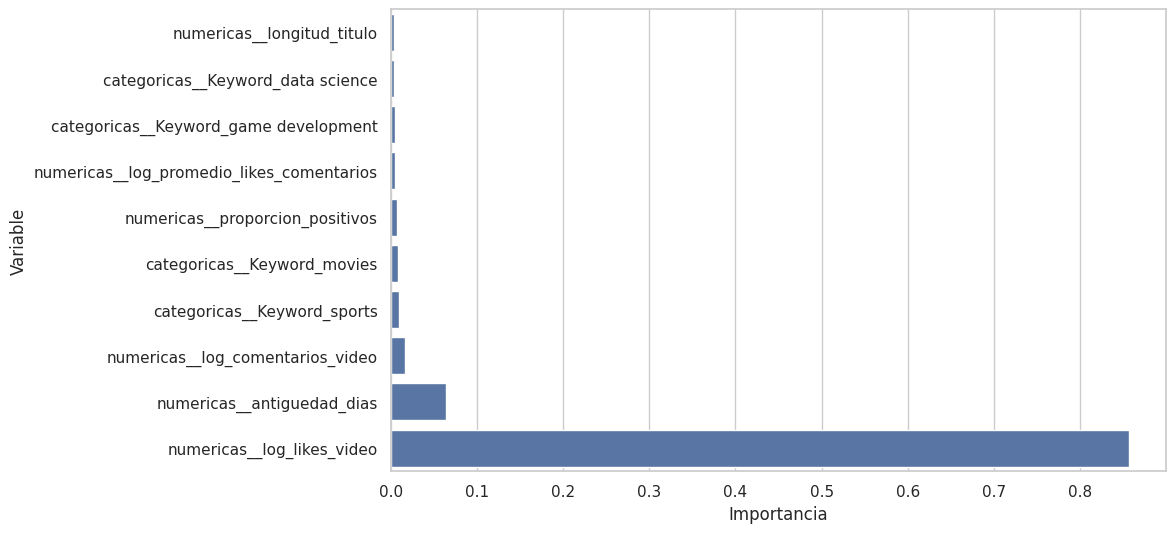

In [30]:
# Obtener el preprocesador y el modelo entrenado
preprocesador_final = mejor_modelo.named_steps["preprocesamiento"]
modelo_final = mejor_modelo.named_steps["modelo"]

# Obtener los nombres finales de las variables
nombres_variables = preprocesador_final.get_feature_names_out()

# Obtener la importancia calculada por Gradient Boosting
importancias = modelo_final.feature_importances_

# Crear una tabla ordenada
tabla_importancias = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": importancias
})

tabla_importancias = (
    tabla_importancias
    .sort_values("Importancia", ascending=False)
    .reset_index(drop=True)
)

print("DIEZ VARIABLES MÁS IMPORTANTES")
display(
    tabla_importancias.head(10).style.format({
        "Importancia": "{:.4f}"
    })
)

# Gráfica de las diez variables más importantes
top_importancias = tabla_importancias.head(10).sort_values(
    "Importancia",
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_importancias,
    x="Importancia",
    y="Variable",
    color="#4c72b0"
)
plt.show()


### Importancia de las variables

El análisis de importancia de variables muestra que la cantidad de likes del video es el predictor con mayor influencia en Gradient Boosting, con una importancia de 0,8568. Esta variable concentra aproximadamente el 85,68 % de la importancia total del modelo, lo cual coincide con la fuerte correlación encontrada entre likes y visualizaciones.

La segunda variable más importante fue la antigüedad del video, con 0,0643. Este resultado indica que el tiempo transcurrido desde la publicación contribuye a explicar la popularidad, debido a que los videos más antiguos han tenido más oportunidades de acumular visualizaciones e interacciones.

La cantidad de comentarios del video ocupó el tercer lugar, con una importancia de 0,0170. Aunque su contribución fue considerablemente menor que la de los likes, continúa siendo una señal relevante de interacción.

Algunas categorías, como deportes, películas, desarrollo de videojuegos y ciencia de datos, también aportaron información al modelo. Sin embargo, su importancia individual fue baja. La proporción de comentarios positivos alcanzó una importancia de 0,0073, mientras que el promedio de likes de los comentarios obtuvo 0,0052. Esto indica que el sentimiento y la recepción de los comentarios contribuyen de manera complementaria, pero tienen menor capacidad predictiva que las métricas generales de interacción.

La longitud del título tuvo una importancia de 0,0038. Aunque previamente presentó una diferencia estadísticamente significativa entre los niveles de popularidad, su aporte dentro del modelo fue reducido.

En general, los resultados indican que la popularidad está explicada principalmente por la interacción directa del video, especialmente por los likes, seguida por su antigüedad y cantidad de comentarios. Las variables relacionadas con el sentimiento y la categoría aportan información adicional, pero no constituyen los predictores principales.

### Limitación de la predicción

La cantidad de likes es una variable altamente relacionada con las visualizaciones y explica gran parte del desempeño del modelo. Sin embargo, ambas métricas se acumulan durante la vida del video. Por esta razón, el modelo debe interpretarse como una herramienta para estimar o clasificar la popularidad actual utilizando información observada de interacción, y no como una predicción completamente anticipada antes de la publicación.

Para una predicción temprana sería necesario disponer de variables medidas durante un periodo específico, por ejemplo, likes y comentarios acumulados durante las primeras 24 o 48 horas. El dataset utilizado no proporciona esta información temporal detallada, lo cual constituye una limitación del proyecto.
``

## 6. Comparación mediante curvas ROC

La curva ROC permite evaluar la capacidad de los modelos para diferenciar entre videos de popularidad alta y baja en distintos umbrales de clasificación. Un valor ROC-AUC cercano a 1 indica una excelente capacidad de discriminación, mientras que un valor de 0,5 corresponde a un comportamiento similar al azar.

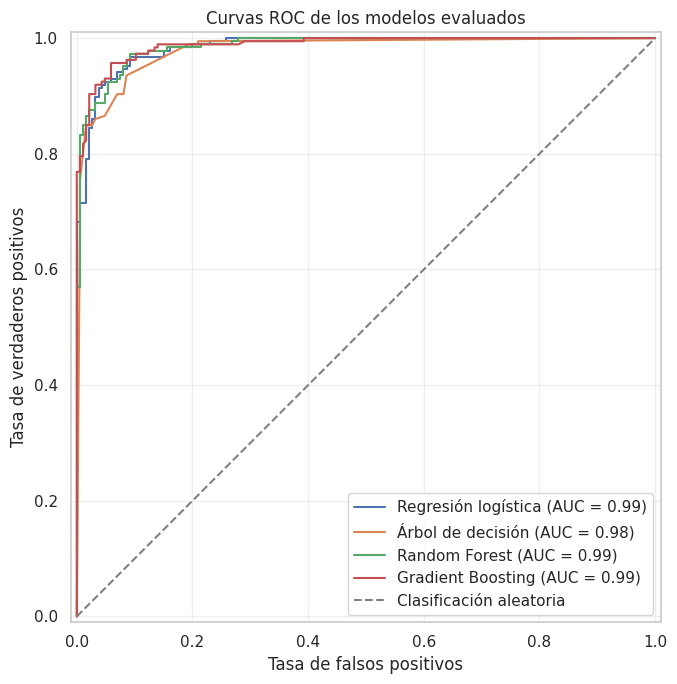

In [32]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(9, 7))

for nombre, pipeline_modelo in modelos_entrenados.items():

    if nombre == "Modelo base":
        continue

    RocCurveDisplay.from_estimator(
        pipeline_modelo,
        X_test,
        y_test,
        name=nombre,
        ax=plt.gca()
    )

# Línea de referencia correspondiente al azar
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

plt.title("Curvas ROC de los modelos evaluados")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de las curvas ROC

Las curvas ROC muestran que los cuatro modelos predictivos tienen una excelente capacidad para diferenciar entre videos de popularidad alta y baja. Todas las curvas se encuentran próximas a la esquina superior izquierda y se mantienen claramente por encima de la línea de clasificación aleatoria.

Gradient Boosting obtuvo el mayor ROC-AUC, con un valor exacto de 0,9880, seguido de Random Forest con 0,9860, regresión logística con 0,9851 y árbol de decisión con 0,9794. En la gráfica, varios valores aparecen redondeados a 0,99 debido a que la leyenda presenta solamente dos cifras decimales.

Aunque las diferencias entre los modelos son pequeñas, Gradient Boosting mantiene el mejor desempeño general al combinar el ROC-AUC más alto con una exactitud de 0,9409 y un F1-score de 0,9402. Estos resultados respaldan su selección como modelo principal.

## 7. Conclusiones

El análisis permitió integrar información de 1.859 videos con las características agregadas de sus comentarios. La preparación incluyó el tratamiento de valores faltantes e inválidos, la eliminación de duplicados, la transformación de variables con valores extremos y la creación de indicadores relacionados con el sentimiento y la interacción de los usuarios.

Los análisis estadísticos mostraron que las visualizaciones presentan una relación especialmente fuerte con los likes del video, con una correlación de Spearman de 0,949. También se identificaron relaciones importantes con la cantidad de comentarios, cuyo coeficiente fue de 0,839, el promedio de likes de los comentarios, con 0,713, y la antigüedad del video, con 0,632.

La prueba U de Mann-Whitney evidenció diferencias estadísticamente significativas entre los videos de popularidad alta y baja en nueve de las diez variables analizadas. La proporción de comentarios negativos fue la única variable que no presentó una diferencia significativa, con un valor p de 0,198432.

Se evaluaron cinco alternativas: un modelo base, regresión logística, árbol de decisión, Random Forest y Gradient Boosting. Esta comparación permitió comprobar que no era suficiente evaluar un único modelo, debido a que era necesario establecer un punto de referencia y analizar la estabilidad de las diferentes alternativas.

Gradient Boosting fue seleccionado como el mejor modelo. En el conjunto de prueba obtuvo una exactitud de 0,9409, precisión de 0,9505, recall de 0,9301, F1-score de 0,9402 y ROC-AUC de 0,9880. El modelo clasificó correctamente 350 de los 372 videos de prueba y cometió 22 errores.

La validación cruzada de cinco particiones confirmó la estabilidad del modelo seleccionado. Gradient Boosting alcanzó un F1-score promedio de 0,9386 y una desviación estándar de 0,0053, superando los resultados promedio de la regresión logística, Random Forest y el árbol de decisión.

La variable más importante fue la cantidad de likes del video, con una importancia de 0,8568, seguida por la antigüedad, con 0,0643, y la cantidad de comentarios, con 0,0170. Las variables de sentimiento, categoría y características del título aportaron información complementaria, pero tuvieron una influencia menor.



In [34]:
# Exportar las tablas principales del análisis

tabla_resultados.to_csv(
    "/comparacion_modelos.csv",
    index=False
)

tabla_validacion.to_csv(
    "/validacion_cruzada.csv",
    index=False
)

tabla_importancias.to_csv(
    "/importancia_variables.csv",
    index=False
)

resultados_pruebas.to_csv(
    "/pruebas_estadisticas.csv",
    index=False
)

correlaciones_visualizaciones.to_csv(
    "/correlaciones_visualizaciones.csv"
)

print("Archivos exportados correctamente:")
print("- comparacion_modelos.csv")
print("- validacion_cruzada.csv")
print("- importancia_variables.csv")
print("- pruebas_estadisticas.csv")
print("- correlaciones_visualizaciones.csv")


Archivos exportados correctamente:
- comparacion_modelos.csv
- validacion_cruzada.csv
- importancia_variables.csv
- pruebas_estadisticas.csv
- correlaciones_visualizaciones.csv


In [35]:
# Exportar el dataset final integrado y procesado

datos.to_csv(
    "/dataset_youtube_procesado.csv",
    index=False
)

print("Dataset procesado exportado correctamente")
print("Dimensiones:", datos.shape)


Dataset procesado exportado correctamente
Dimensiones: (1859, 25)
